# 01. DAS adoption: topic frame and abstract-level semantic screen

**Goal.** Measure how much of the distributed acoustic sensing (DAS) literature uses AI as a method, replacing the keyword counts in proposal Fig. 2B with a semantic label.

**Inputs (frozen, hash-checked).** `data/semantic_screen/das_topic_2026-10-29/`: the screen rows (title, model labels, rationale; no abstracts), an abstract-free index of the 1,423 harvested works, and the harvest, prepare, batch and collect receipts.

**Method.**
1. *Frame.* `standalone/config.das_topic.json`: every OpenAlex work typed article or review whose title or abstract matches `"distributed acoustic sensing"`, one query per year 2020 to 2025, cursor-paged (`standalone/literature_study.py harvest`).
2. *Screen.* `tools/ai_readiness/semantic_screen.py` sends title plus reconstructed abstract to Claude Opus 5.5 (effort medium, structured JSON output) with the codebook `tools/ai_readiness/semantic_screen_codebook_v0.1.md`. Labels: `ai_role`, AI method families, measurement families, `das_used`, confidence, rationale. A missing abstract is `unclear`, never negative.
3. *Aggregate.* Shares are among rows with a non-`unclear` label; unclear and missing counts are reported beside them.

**Status.** Unvalidated. The 130-abstract human validation sample has been drawn (`validation_design.json`) but not coded. Nothing here is an actual-use label.

In [1]:
import json, csv, hashlib, os, subprocess, sys
from collections import Counter, defaultdict
from pathlib import Path
from IPython.display import Image, Markdown, display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pixi.toml").exists())
sys.path.insert(0, str(ROOT / "tools"))
def table(header, rows):
    """Render rows as a Markdown table."""
    lines = ["| " + " | ".join(header) + " |", "|" + "---|" * len(header)]
    lines += ["| " + " | ".join(str(c) for c in r) + " |" for r in rows]
    display(Markdown("\n".join(lines)))
print("repository root:", ROOT)

repository root: /Users/marinedenolle/GitHub/geoscience-ai-readiness


## 1. Verify the frozen inputs

In [2]:
D = ROOT / "data/semantic_screen/das_topic_2026-10-29"
manifest = json.loads((D / "MANIFEST.json").read_text())
checks = {name: hashlib.sha256((D / name).read_bytes()).hexdigest() == digest for name, digest in manifest["files"].items()}
print(f"{sum(checks.values())} of {len(checks)} frozen files match MANIFEST.json")
assert all(checks.values())
print("excluded from Git and how to regenerate:")
for k, v in manifest["excluded"].items():
    print(" -", k, ":", v)

10 of 10 frozen files match MANIFEST.json
excluded from Git and how to regenerate:
 - works.jsonl : full OpenAlex records with inverted-index abstracts (30.8 MB); regenerate with pixi run -e semantic das-harvest
 - requests.jsonl : batch requests containing abstract text; regenerate with das-screen-prepare
 - validation_template.jsonl, validation_coder_*.csv : contain abstracts; regenerate with validation-sample and the same seed


## 2. The classifier and the run that produced the labels

In [3]:
prep = json.loads((D / "prepare_manifest.json").read_text())
batch = json.loads((D / "batch.json").read_text())
coll = json.loads((D / "collect_manifest.json").read_text())
table(["Item", "Value"], [
    ["Model", prep["model"]], ["Effort", prep["effort"]], ["Codebook version", prep["codebook_version"]],
    ["Prompt SHA256 (system prompt + schema + model + effort)", prep["prompt_sha256"][:16] + "..."],
    ["Works / requests / missing abstract", f'{prep["works"]} / {prep["requests"]} / {prep["missing_abstract"]}'],
    ["Batch", batch["id"]], ["Submitted / collected (UTC)", f'{batch["submitted_at"][:16]} / {coll["collected_at"][:16]}'],
    ["Row statuses", ", ".join(f"{k}: {v}" for k, v in coll["statuses"].items())],
    ["Recorded cost (batch prices)", f'${coll["usd_total"]:.2f}'],
])
from ai_readiness import semantic_screen as ss
print("Prompt hash recomputed from the current codebook matches the run:", ss.prompt_sha256(prep["model"], prep["effort"]) == prep["prompt_sha256"])

| Item | Value |
|---|---|
| Model | claude-opus-5-5 |
| Effort | medium |
| Codebook version | 0.1.0 |
| Prompt SHA256 (system prompt + schema + model + effort) | fea5a7ace5f4c907... |
| Works / requests / missing abstract | 1423 / 1264 / 159 |
| Batch | msgbatch_01HdBu5onQdhwxu6adW2ZjqL |
| Submitted / collected (UTC) | 2026-10-29T21:02 / 2026-10-29T21:16 |
| Row statuses | missing_abstract: 159, labeled: 1262, rationale_too_long_or_missing: 2 |
| Recorded cost (batch prices) | $4.48 |

Prompt hash recomputed from the current codebook matches the run: True


## 3. Per-year results

In [4]:
summary = json.loads((D / "summary.json").read_text())
rows = []
for y in summary["years"]:
    a = y["ai_as_method_among_das_confirmed"]
    lo, hi = a["wilson95"]
    rows.append([y["year"], y["works"], y["abstract_missing"], y["das_used_counts"]["yes"], a["count"], a["denominator"],
                 f'{100*a["share"]:.1f}%', f"{100*lo:.1f} to {100*hi:.1f}%"])
table(["Year", "Works", "No abstract", "Analysis uses DAS", "AI as method", "Denominator", "Share", "Wilson 95%"], rows)

| Year | Works | No abstract | Analysis uses DAS | AI as method | Denominator | Share | Wilson 95% |
|---|---|---|---|---|---|---|---|
| 2020 | 118 | 18 | 85 | 13 | 85 | 15.3% | 9.2 to 24.4% |
| 2021 | 137 | 10 | 98 | 16 | 98 | 16.3% | 10.3 to 24.9% |
| 2022 | 193 | 17 | 142 | 26 | 142 | 18.3% | 12.8 to 25.5% |
| 2023 | 238 | 25 | 188 | 42 | 186 | 22.6% | 17.2 to 29.1% |
| 2024 | 312 | 34 | 244 | 59 | 243 | 24.3% | 19.3 to 30.0% |
| 2025 | 425 | 55 | 325 | 93 | 325 | 28.6% | 24.0 to 33.8% |

## 4. Semantic screen against the keyword series it replaces

The keyword series is the frozen 21 October 2026 snapshot: DAS works whose title or abstract also contains "machine learning" or "deep learning". The semantic share here uses the same population, all labeled DAS works.

In [5]:
kw = defaultdict(dict)
with open(ROOT / "legacy/community_demand/annual_title_abstract_article_review_counts.csv") as f:
    for r in csv.DictReader(f):
        kw[r["query_id"]][int(r["year"])] = int(r["count"])
screen = [json.loads(l) for l in open(D / "screen_semantic.jsonl")]
lab = [r for r in screen if r["status"] == "labeled" and r["ai_role"] != "unclear"]
rows = []
for y in range(2020, 2026):
    g = [r for r in lab if r["year"] == y]; k = sum(r["ai_role"] == "ai_as_method" for r in g)
    rows.append([y, f'{100*kw["das_ml_article_review"][y]/kw["das_article_review"][y]:.1f}%', f"{100*k/len(g):.1f}%"])
table(["Year", "Keyword co-occurrence", "Semantic: AI as a method"], rows)

| Year | Keyword co-occurrence | Semantic: AI as a method |
|---|---|---|
| 2020 | 10.2% | 15.2% |
| 2021 | 9.5% | 14.2% |
| 2022 | 10.8% | 16.0% |
| 2023 | 14.3% | 20.7% |
| 2024 | 13.5% | 21.8% |
| 2025 | 16.7% | 25.9% |

## 5. Who publishes DAS work, and how often with AI

Venue and OpenAlex field come from the abstract-free works index. Field labels are assigned by OpenAlex from content, so AI-heavy papers drift into Computer Science; the venue split avoids that.

In [6]:
index = {w["paper_id"]: w for w in (json.loads(l) for l in open(D / "works_index.jsonl"))}
das = [r for r in lab if r["das_used"] == "yes"]
by_venue = defaultdict(lambda: [0, 0])
for r in das:
    v = index[r["paper_id"]]["venue"] or "none"
    by_venue[v][1] += 1; by_venue[v][0] += r["ai_role"] == "ai_as_method"
rows = [[v, n, a, f"{100*a/n:.0f}%"] for v, (a, n) in sorted(by_venue.items(), key=lambda kv: -kv[1][1])[:12]]
table(["Venue", "DAS-using papers", "AI as method", "Share"], rows)

| Venue | DAS-using papers | AI as method | Share |
|---|---|---|---|
| Geophysics | 91 | 23 | 25% |
| Seismological Research Letters | 62 | 12 | 19% |
| Sensors | 56 | 19 | 34% |
| Geophysical Journal International | 49 | 8 | 16% |
| Journal of Lightwave Technology | 46 | 8 | 17% |
| Journal of Geophysical Research Solid Earth | 42 | 4 | 10% |
| Optics Express | 41 | 9 | 22% |
| The Leading Edge | 37 | 5 | 14% |
| IEEE Sensors Journal | 36 | 11 | 31% |
| SPE Journal | 33 | 2 | 6% |
| IEEE Transactions on Geoscience and Remote Sensing | 32 | 25 | 78% |
| Geophysical Research Letters | 28 | 3 | 11% |

## 6. Figures (rebuilt from the frozen screen)

['explore_1_keyword_vs_semantic.png', 'explore_2_ai_role_by_year.png', 'explore_3_ai_method_families.png', 'explore_4_co_measured_families.png']


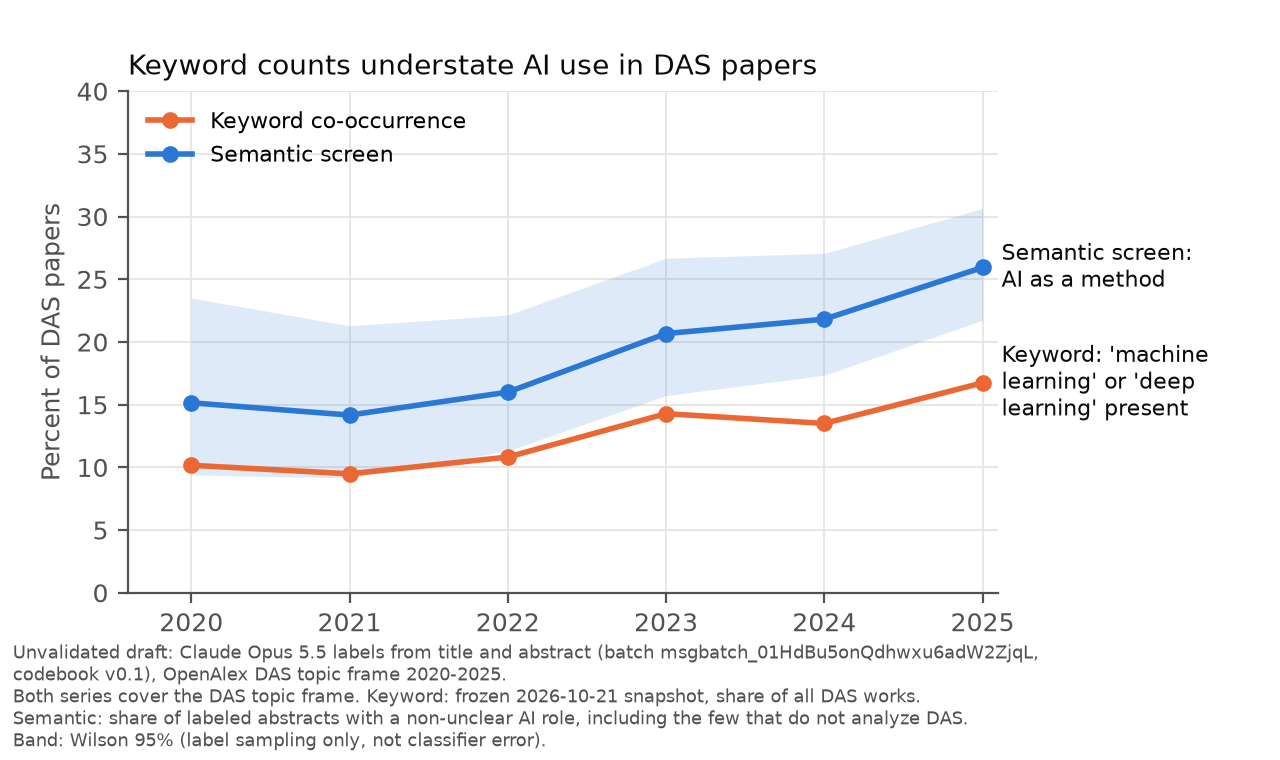

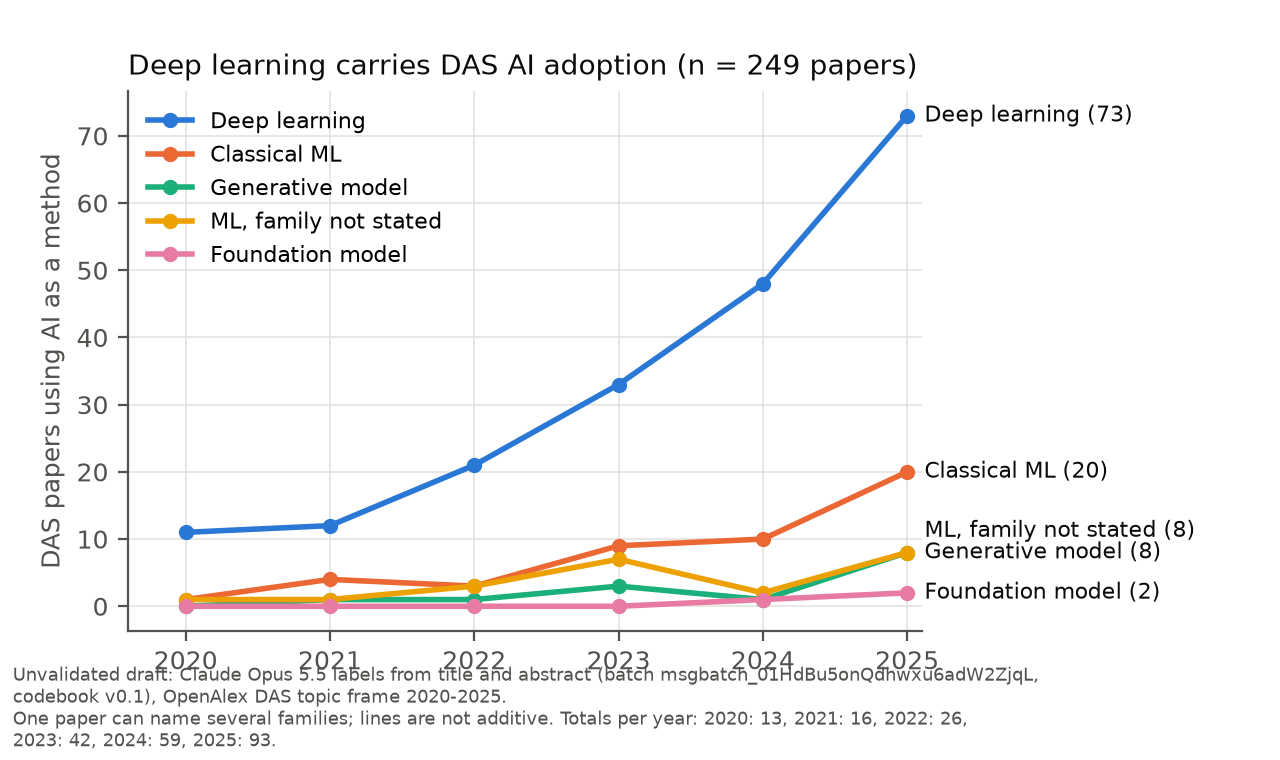

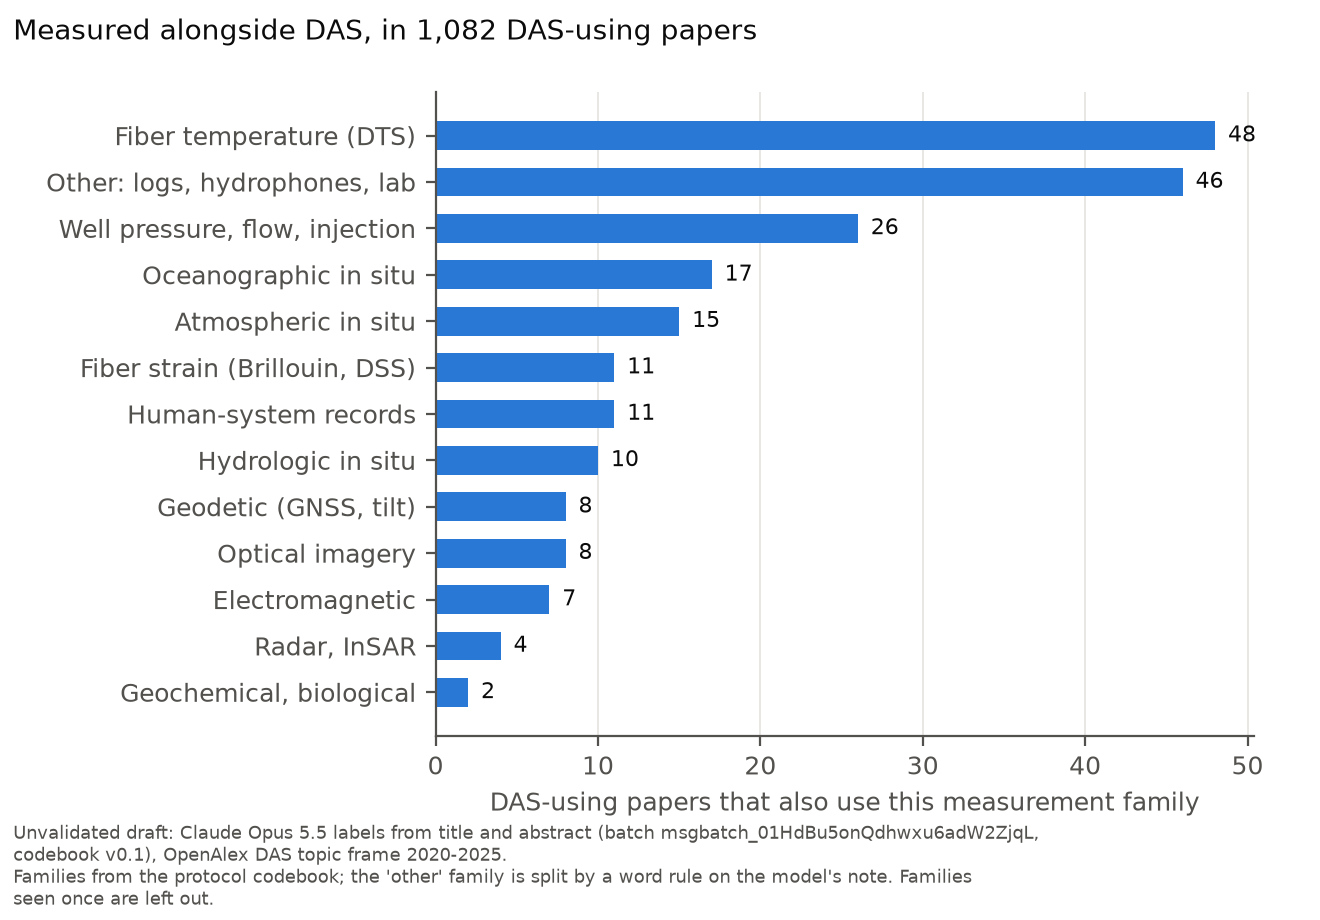

In [7]:
subprocess.run([sys.executable, str(ROOT / "scripts/explore_das_semantic.py")], check=True, cwd=ROOT)
for name in ("explore_1_keyword_vs_semantic", "explore_3_ai_method_families", "explore_4_co_measured_families"):
    display(Image(filename=str(ROOT / "build/das_semantic" / f"{name}.png"), width=720))

## 7. Re-running the screen from scratch

The labels above came from one paid batch. To reproduce them independently (costs about $4.50 at batch prices; needs your own `OPENALEX_API_KEY` and Claude credentials):

```sh
pixi run -e semantic das-harvest            # 18 OpenAlex pages into runs/das_topic_<date>
pixi run -e semantic das-screen-prepare     # offline: requests, estimate, prompt hash
pixi run -e semantic das-screen-pilot       # 5 abstracts, synchronous
pixi run -e semantic das-screen-submit      # one Message Batch, refuses above $40
pixi run -e semantic das-screen-collect     # writes screen_semantic.jsonl
pixi run -e semantic das-screen-aggregate
```

A new run gives a new harvest (OpenAlex grows by a few records) and fresh model samples, so expect small differences in counts; the prompt hash guarantees the same classifier definition.